<a href="https://colab.research.google.com/github/WeridFire/QuantumComputing/blob/main/assignment1/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1 - State‑Vector Quantum Computer Simulator
You will build a minimal state‑vector simulator and use it to simulate a 2‑qubit Bell circuit. A state‑vector simulator represents the quantum state as a complex vector and applies gates as matrices.

> Convention: We use computational basis ordering |q0 q1> with q0 as the most significant qubit (MSB). The basis is |00>,|01>,|10>,|11> → indices [0,1,2,3].

## Task 1.1 - State‑vector representation
Getting the basis and normalization right prevents subtle bugs later (wrong amplitudes, swapped qubits). This is the foundation for applying gates and interpreting measurements.

> What the code does: Creates and normalizes a 4‑dimensional complex vector for a 2‑qubit system, initializing it to |00> or |0>.

In [1]:
import numpy as np

DTYPE = np.complex128

def ket00():
    """Return |00> as a length‑4 complex column vector."""
    v = np.zeros(4, dtype=DTYPE)
    v[0] = 1.0
    return v

def normalize(v: np.ndarray) -> np.ndarray:
    n = np.linalg.norm(v)
    if n == 0:
        raise ValueError("Zero vector cannot be normalized.")
    return v / n

# Example
psi = ket00()
assert np.isclose(np.linalg.norm(psi), 1.0)

> What to include. A short sentence describing your basis ordering and how you map bitstrings to indices.

### Our Solution

We adopt the standard computational basis ordering $\vert{}q_0 q_1\rangle$, where $q_0$ is the most significant qubit (MSB) and $q_1$ is the least significant qubit (LSB). Each two-qubit basis state directly maps to its integer array index via the standard binary representation.

## Task 1.2 - Quantum gate implementation

Gates are linear operators. Building them once and applying correctly to the target qubit makes later circuits easy to reason about and unit‑test.

> What the code does: Defines Hadamard and CNOT matrices and utilities to apply them in the 2‑qubit basis.

In [2]:
# 1‑qubit and 2‑qubit gate definitions (matrix form)
I2 = np.array([[1, 0], [0, 1]], dtype=DTYPE)
H  = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=DTYPE)

# CNOT with control = q0 (MSB), target = q1 (LSB) in basis |q0 q1>
CNOT_01 = np.array([
    [1,0,0,0],
    [0,1,0,0],
    [0,0,0,1],
    [0,0,1,0]
], dtype=DTYPE)

# Expand a 1‑qubit unitary U to a 2‑qubit operator acting on target qubit t in |q0 q1> order
# t = 0 applies to q0 (MSB); t = 1 applies to q1 (LSB)

def expand_1q(U: np.ndarray, t: int) -> np.ndarray:
    if t == 0:   # act on q0 (MSB)
        return np.kron(U, I2)
    elif t == 1: # act on q1 (LSB)
        return np.kron(I2, U)
    else:
        raise ValueError("target index must be 0 or 1")

# Apply a gate matrix to a state vector

def apply(U: np.ndarray, psi: np.ndarray) -> np.ndarray:
    return U @ psi

# Quick unit tests
assert np.allclose(H.conj().T @ H, I2)
assert np.allclose(CNOT_01.conj().T @ CNOT_01, np.eye(4))

> What to include. Briefly justify your control/target convention for CNOT and how it matches the basis ordering.

### Our Solution

We define the CNOT matrix using the convention where $q_0$ is the control and $q_1$ is the target. In our $|q_0 q_1\rangle$ basis ordering, this results in a block-diagonal matrix:

*   If $q_0 = 0$ (indices 0 and 1), the identity $I_2$ is applied to $q_1$.
*   If $q_0 = 1$ (indices 2 and 3), the Pauli-X gate is applied to $q_1$.

This leads to the matrix representation (also present in the code above):
$$\text{CNOT}_{01} = \begin{pmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & 1 & 0 \end{pmatrix}$$


##Task 1.3 - Circuit simulation: Bell state

The Bell state is the simplest non‑separable state. Simulating it shows how interference from H, combined with a single controlled operation, produces entanglement.

> What the code does: Applies H on q0 then CNOT(q0→q1) to produce |Φ+> = (|00>+|11>)/√2.

In [3]:
def bell_state() -> np.ndarray:
    psi = ket00()
    # H on q0 (MSB), then CNOT(control=q0, target=q1)
    psi = apply(expand_1q(H, t=0), psi)
    psi = apply(CNOT_01, psi)
    return normalize(psi)

psi_bell = bell_state()
print("Bell state vector:", np.round(psi_bell, 6))
# Expected amplitudes (up to a global phase): [1/√2, 0, 0, 1/√2]

Bell state vector: [0.707107+0.j 0.      +0.j 0.      +0.j 0.707107+0.j]


> What to include. Print the final state and confirm it matches ( |00> + |11> ) / √2 up to global phase.

### Our Solution
Compiling the code above the result is the following:

```
Bell state vector: [0.707107+0.j 0.      +0.j 0.      +0.j 0.707107+0.j]
```

which correspond exactly to:

( |00> + |11> ) / √2

##Task 1.4 - Output, verification, and circle‑plot comparison

Bridge amplitudes -> measurement outcomes, and verify your simulator against expectations. Visualization connects algebra to intuitive structure.

> What the code does: Samples bitstrings from the state, plots a histogram, and compare to earlier work.

{'00': 4983, '01': 0, '10': 0, '11': 5017}


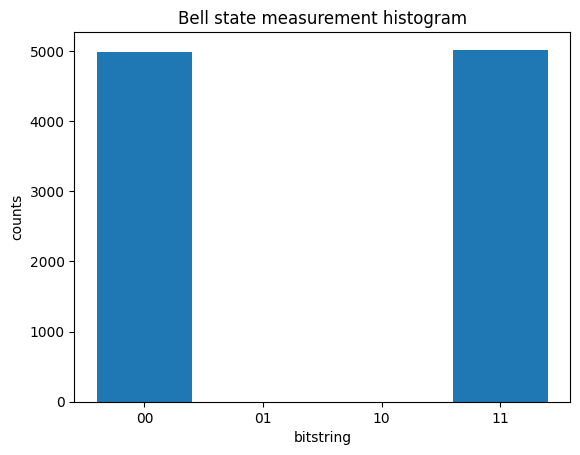

In [4]:
import matplotlib.pyplot as plt

BITSTR = ["00","01","10","11"]

def sample_bitstrings(psi: np.ndarray, shots: int = 10_000, seed: int = 7):
    rng = np.random.default_rng(seed)
    probs = np.abs(psi)**2
    idx = rng.choice(4, size=shots, p=probs)
    return idx

# Sample from Bell state
shots = 10_000
idx = sample_bitstrings(psi_bell, shots=shots)

# Make histogram
counts = {b: int(np.sum(idx == i)) for i, b in enumerate(BITSTR)}
print(counts)
plt.bar(counts.keys(), counts.values())
plt.xlabel("bitstring"); plt.ylabel("counts"); plt.title("Bell state measurement histogram")
plt.show()

> What to include:
   - Circle‑notation visualization. Use your lecture function to visualize (in circle notation, see here, for instance) psi_bell

  - Compare and reflect. Do the counts match expectations within sampling error? How does the circle plot show two dominant components |00> and |11> and their relative phase?

Let's first setup enviroment for the lecture code

In [5]:
!pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.9 MB/s eta 0:00:00


QbitSystem Class with his functions

In [6]:
import math
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

class QubitSystem:
    def __init__(self, statevector: np.ndarray, label: str = "Qubit System"):
        self.label = label
        self.set_statevector(statevector)

    def set_statevector(self, statevector: np.ndarray):
        sv = np.asarray(statevector, dtype=np.complex128).flatten()
        if sv.ndim != 1:
            raise ValueError("Statevector must be 1D.")
        n_states = sv.size
        n_qubits = int(round(math.log2(n_states)))
        if 2**n_qubits != n_states:
            raise ValueError("Length must be a power of 2.")
        # Defensive normalization (harmless if already normalized)
        norm = np.linalg.norm(sv)
        if norm != 0 and not np.isclose(norm, 1.0):
            sv = sv / norm

        self.n_qubits = n_qubits
        self.n_states = n_states
        self.amps  = sv
        self.prob  = np.abs(sv)**2
        self.phase = np.angle(sv)

    def viz_circle(self, max_cols: int = 8, figsize_scale: float = 2.3):
        cols = max(1, min(max_cols, self.n_states))
        rows = int(math.ceil(self.n_states / cols))

        fig, axes = plt.subplots(
            rows, cols,
            figsize=(cols*figsize_scale, rows*(figsize_scale+0.2))
        )
        axes = np.atleast_2d(axes)

        def bitstr(i: int, n: int) -> str:
            return format(i, f"0{n}b")

        for idx in range(rows * cols):
            r, c = divmod(idx, cols)
            ax = axes[r, c]
            ax.set_aspect("equal")
            ax.set_xlim(0, 1); ax.set_ylim(0, 1)
            ax.axis("off")

            if idx >= self.n_states:
                ax.set_visible(False)
                continue

            # Outer reference circle
            ax.add_patch(plt.Circle((0.5, 0.5), 0.48, fill=False, lw=1.0, alpha=0.5))

            # Filled disk: radius ∝ sqrt(probability) so area ∝ probability
            radius = 0.48 * np.sqrt(self.prob[idx])
            ax.add_patch(plt.Circle((0.5, 0.5), radius, alpha=0.25))

            # Phase arrow
            angle = self.phase[idx]
            L = 0.45
            x2 = 0.5 + L * np.cos(angle)
            y2 = 0.5 + L * np.sin(angle)
            ax.arrow(0.5, 0.5, x2 - 0.5, y2 - 0.5,
                     head_width=0.03, head_length=0.05, length_includes_head=True)

            ax.set_title(f"|{bitstr(idx, self.n_qubits)}⟩", fontsize=10)

        fig.suptitle(self.label, fontsize=12)
        plt.tight_layout()
        plt.show()

Inverse function too:

In [7]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

def sv_from_circ(circ: QuantumCircuit) -> np.ndarray:
    """Extract a numpy complex vector from a Qiskit QuantumCircuit."""
    sv = Statevector(circ)
    return np.asarray(sv, dtype=np.complex128)

### Our Solution


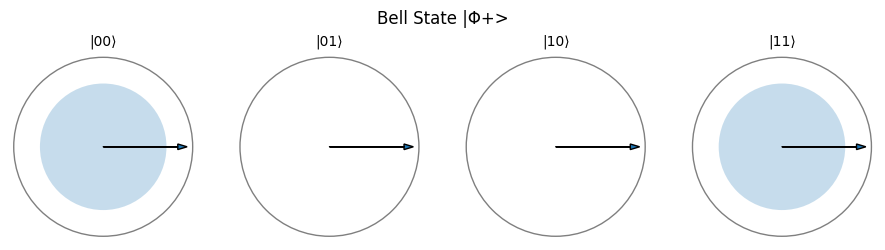

Measurement counts: {'00': 4983, '01': 0, '10': 0, '11': 5017}
Theoretical probability for |00>: 0.50
Theoretical probability for |11>: 0.50


In [8]:
# Initialize the QubitSystem with our psi_bell calculated in Task 1.3
bell_system = QubitSystem(psi_bell, label="Bell State |Φ+>")

# Visualize using circle notation
bell_system.viz_circle()

# Verification analysis
print(f"Measurement counts: {counts}")
print(f"Theoretical probability for |00>: {np.abs(psi_bell[0])**2:.2f}")
print(f"Theoretical probability for |11>: {np.abs(psi_bell[3])**2:.2f}")

### Comparison and Reflection

The theoretical probability for a Bell state $|\Phi^+\rangle = \frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$ is $0.5$ for both $|00\rangle$ and $|11\rangle$, and $0$ for $|01\rangle$ and $|10\rangle$. Our sampled counts (4983 for $|00\rangle$ and 5017 for $|11\rangle$) result in experimental probabilities of 0.498 and 0.502 respectively. These are coherent with the standard sampling error (which is approximately $1/\sqrt{10000} = 0.01$ for 10,000 mesurements).

About the circle plot:
*   Dominant Components: The plot shows two large filled disks for $|00\rangle$ and $|11\rangle$, while $|01\rangle$ and $|10\rangle$ have empty circles. This visually confirms the state is a superposition.
*   Relative Phase: The arrows in both the $|00\rangle$ and $|11\rangle$ circles point in the same direction (angle 0).